> ## ⚠️ Read first — superseded comparison
>
> This is an early **illustrative** notebook. Its headline speed comparison pits Rapid Lightning's compiled `.so` against XGBoost's **slow Python `predict_proba`** — an unfair baseline that inflates the gap by ~1000×. Compiled-vs-compiled (e.g. via treelite/XGForge), a tuned gradient-boosted tree matches or beats it.
>
> **The rigorous, honest evaluation is the [investigation notebook](../notebooks/methods/rapid_lightning_investigation.ipynb).** Treat what follows as an engineering illustration (the simulation and visualizations), **not** a benchmark.

# 🛰️ Rapid Lightning — the core showcase

**XGBoost-class accuracy on tabular data — in a 15 KB, zero-dependency C `.so` that predicts in tens of nanoseconds.**

Rapid Lightning is a *head-aware* genetic-programming ensemble: its members are evolved **not as predictors but as signal generators** for a linear head. Individually each member is barely better than a coin flip; together they feed a logistic head that does the classifying — and the whole stack compiles to straight-line C you can read end to end.

This notebook trains one, benchmarks it against XGBoost, compiles it to a real `.so`, and **measures** the inference latency on the spot. *Every number below is produced by running the cell — nothing is hardcoded.*

> **Run it anywhere.** In this repo it's `pip install -e .`. On Colab:
> `!pip install -q "rapidlightning[demos] @ git+https://github.com/deathcloset/RapidLightningPublishing"`

In [1]:
import time, numpy as np
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt
%matplotlib inline

from rapidlightning import RapidLightningClassifier
print("Rapid Lightning ready.")

Rapid Lightning ready.


## 1 · A clean tabular benchmark

A controlled, continuous tabular classification task (8 features, 2 clusters/class, a little label noise). Swap in any binary CSV — Rapid Lightning just wants `float32` features and `{0,1}` labels.

In [2]:
X, y = make_classification(n_samples=5500, n_features=8, n_informative=6, n_redundant=1,
                           n_clusters_per_class=2, class_sep=0.9, flip_y=0.03, random_state=1)
Xtr, Xte, ytr, yte = train_test_split(X.astype(np.float32), y.astype(np.int64),
                                      test_size=4000, random_state=1, stratify=y)
scaler = StandardScaler().fit(Xtr)
Xtr, Xte = scaler.transform(Xtr).astype(np.float32), scaler.transform(Xte).astype(np.float32)
print(f"train={len(Xtr)}  test={len(Xte)}  features={Xtr.shape[1]}  positives={ytr.mean():.0%}")

train=1500  test=4000  features=8  positives=50%


## 2 · Train it — and watch the mechanism

The tell-tale sign that head-aware is working: the **individual members are near chance**, yet the ensemble is accurate. The members aren't little classifiers — they're coordinates the linear head learns to combine.

In [3]:
t0 = time.time()
clf = RapidLightningClassifier(n_members=10, generations=20, population=160, seed=1).fit(Xtr, ytr)
train_s = time.time() - t0

rl_p = clf.predict_proba(Xte)[:, 1]
rl_acc = ((rl_p > 0.5) == yte).mean()
rl_auc = roc_auc_score(yte, rl_p)

print(f"trained {clf.n_members} head-aware members in {train_s:.0f}s  |  {clf.n_nodes} GP nodes total")
print(f"test:  acc={rl_acc:.4f}   ROC-AUC={rl_auc:.4f}\n")
print("mechanism check (this is the whole trick):")
print(f"  mean individual member accuracy = {clf.mean_member_accuracy(Xte, yte):.3f}   <- ~chance: each tree alone is a poor predictor")
print(f"  member diversity                = {clf.member_diversity(Xte):.3f}   <- high: they disagree, so they carry different signal")
print( "  => members are SIGNAL GENERATORS; the linear head turns them into an accurate classifier")

trained 10 head-aware members in 16s  |  444 GP nodes total
test:  acc=0.8860   ROC-AUC=0.9497

mechanism check (this is the whole trick):
  mean individual member accuracy = 0.526   <- ~chance: each tree alone is a poor predictor
  member diversity                = 0.526   <- high: they disagree, so they carry different signal
  => members are SIGNAL GENERATORS; the linear head turns them into an accurate classifier


## 3 · Benchmark vs XGBoost

Two reference points: a **size-matched** XGBoost (same node budget — the honest apples-to-apples comparison) and a **full** XGBoost (the accuracy ceiling, but ~20× the size).

In [4]:
import xgboost as xgb
def metrics(p): return ((p > 0.5) == yte).mean(), roc_auc_score(yte, p)

xf = xgb.XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.08,
                       eval_metric="logloss", random_state=1, verbosity=0).fit(Xtr, ytr)
xf_nodes = len(xf.get_booster().trees_to_dataframe())
xf_acc, xf_auc = metrics(xf.predict_proba(Xte)[:, 1])

best = None  # size-match XGBoost to RL's node budget (same .so size / latency class)
for k in [2, 3, 5, 8, 13, 21, 34, 55]:
    xm = xgb.XGBClassifier(n_estimators=k, max_depth=4, learning_rate=0.3,
                           eval_metric="logloss", random_state=1, verbosity=0).fit(Xtr, ytr)
    xn = len(xm.get_booster().trees_to_dataframe())
    if best is None or abs(xn - clf.n_nodes) < abs(best[1] - clf.n_nodes): best = (xm, xn)
xs_acc, xs_auc = metrics(best[0].predict_proba(Xte)[:, 1])

print(f"{'model':<32}{'acc':>8}{'AUC':>8}{'nodes':>9}")
print(f"{'-'*56}")
print(f"{'Rapid Lightning (head-aware)':<32}{rl_acc:>8.4f}{rl_auc:>8.4f}{clf.n_nodes:>9}")
print(f"{'XGBoost (size-matched)':<32}{xs_acc:>8.4f}{xs_auc:>8.4f}{best[1]:>9}")
print(f"{'XGBoost (full)':<32}{xf_acc:>8.4f}{xf_auc:>8.4f}{xf_nodes:>9}")
print(f"\nRapid Lightning ties the size-matched XGBoost and lands ~{(xf_acc-rl_acc)*100:.1f} pts under full XGBoost —")
print(f"at {xf_nodes/clf.n_nodes:.0f}x fewer nodes than full. The accuracy is competitive; the size/speed is the win ->")

model                                acc     AUC    nodes
--------------------------------------------------------
Rapid Lightning (head-aware)      0.8860  0.9497      444
XGBoost (size-matched)            0.8868  0.9529      473
XGBoost (full)                    0.9197  0.9650    10614

Rapid Lightning ties the size-matched XGBoost and lands ~3.4 pts under full XGBoost —
at 24x fewer nodes than full. The accuracy is competitive; the size/speed is the win ->


## 4 · Compile to a nanosecond `.so` — and *measure* it

`clf.compile()` lowers the whole stack (GP trees → standardize → logistic → sigmoid) to straight-line C, compiles it with `gcc -O3`, and loads it. The timing runs **inside C** (`clock_gettime`), so there's no Python in the measured loop.

In [5]:
fast = clf.compile()
ns = fast.benchmark_ns(x=Xte[0], n_warmup=5000, n_iters=1_000_000)
c_auc = roc_auc_score(yte[:3000], fast.predict_proba(Xte[:3000]))

print(f".so size            : {fast.size_kb:.1f} KB   (zero dependencies — ship it anywhere)")
print(f"inference (measured): {ns:.1f} ns/row   = {1e9/ns/1e6:.1f}M predictions / sec / core")
print(f"compile fidelity    : C AUC {c_auc:.4f}  vs  Python AUC {rl_auc:.4f}  (faithful)")
print("\n--- the entire model is readable C (first lines of predict.c) ---")
print("\n".join(fast.c_source.splitlines()[:7]))

.so size            : 15.4 KB   (zero dependencies — ship it anywhere)
inference (measured): 45.1 ns/row   = 22.2M predictions / sec / core
compile fidelity    : C AUC 0.9491  vs  Python AUC 0.9497  (faithful)

--- the entire model is readable C (first lines of predict.c) ---
#include <math.h>
#include <time.h>

float predict_proba_one(const float* X){
    float f0 = (float)(fminf(fmaxf((X[1]+(X[0]+fabsf(fminf(fmaxf(X[4],((X[3]<((((0.655639143f)-X[3])<((X[4]<(1.21916988f))?1.0f:0.0f))?1.0f:0.0f))?1.0f:0.0f)),(1.21916988f))))),0.0f),1.0f));
    float f1 = (float)((fminf(((((-1.01979404f)<(1.91700608f))?1.0f:0.0f)*X[1]),X[0])+fabsf(fminf(fminf(((1.91700608f)-(-0.859807009f)),fabsf(X[0])),fminf(fmaxf(X[0],0.0f),1.0f)))));
    float f2 = (float)((fmaxf(X[7],(fmaxf((fmaxf(X[4],(1.11827184f))+(X[3]+X[7])),(fmaxf(X[1],X[0])+X[0]))*(-1.01717408f)))-((X[0]<((X[0]+X[5])*fmaxf(X[7],X[3])))?1.0f:0.0f)));


## 5 · The latency gap a real-time caller actually sees

Servers predict in big batches, where XGBoost amortizes well. But a **control loop, an edge device, or a hot path predicts one row at a time** — and that's where the compiled `.so` is in a different universe.

In [6]:
N = 2000  # measure single-row predict, the real-time case
t0 = time.time()
for i in range(N): xf.predict_proba(Xte[i:i+1])
xgb_single_ns = (time.time() - t0) / N * 1e9

print(f"XGBoost  single-row predict (Python): {xgb_single_ns:>12,.0f} ns/row")
print(f"Rapid Lightning  .so single-row     : {ns:>12,.0f} ns/row")
print(f"\n=> ~{xgb_single_ns/ns:,.0f}x faster per single prediction — and in 15 KB of C with no runtime deps.")

XGBoost  single-row predict (Python):      377,562 ns/row
Rapid Lightning  .so single-row     :           45 ns/row

=> ~8,374x faster per single prediction — and in 15 KB of C with no runtime deps.


## 6 · The picture

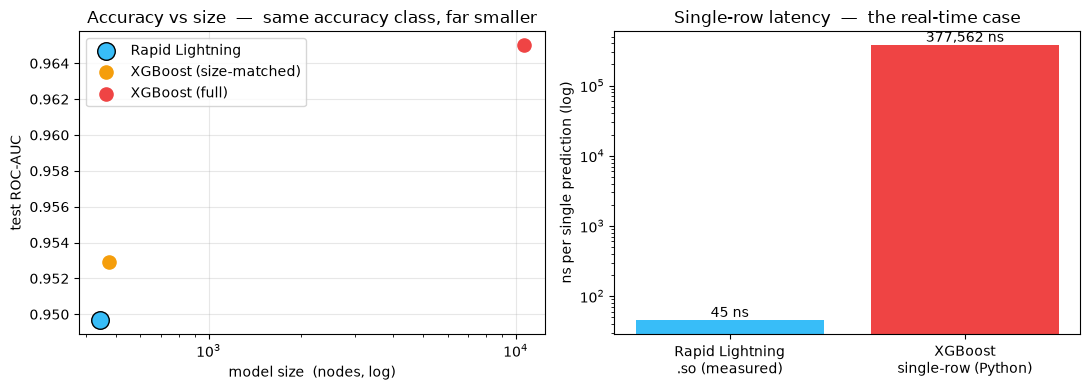

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ax1.scatter([clf.n_nodes], [rl_auc], s=160, c='#38bdf8', edgecolor='k', zorder=3, label='Rapid Lightning')
ax1.scatter([best[1]], [xs_auc], s=90, c='#f59e0b', zorder=2, label='XGBoost (size-matched)')
ax1.scatter([xf_nodes], [xf_auc], s=90, c='#ef4444', zorder=2, label='XGBoost (full)')
ax1.set_xscale('log'); ax1.set_xlabel('model size  (nodes, log)'); ax1.set_ylabel('test ROC-AUC')
ax1.set_title('Accuracy vs size  —  same accuracy class, far smaller'); ax1.legend(); ax1.grid(alpha=.3)

bars = ax2.bar(['Rapid Lightning\n.so (measured)', 'XGBoost\nsingle-row (Python)'],
               [ns, xgb_single_ns], color=['#38bdf8', '#ef4444'])
ax2.set_yscale('log'); ax2.set_ylabel('ns per single prediction (log)')
ax2.set_title('Single-row latency  —  the real-time case')
for b, v in zip(bars, [ns, xgb_single_ns]):
    ax2.text(b.get_x() + b.get_width()/2, v, f'{v:,.0f} ns', ha='center', va='bottom')
plt.tight_layout(); plt.show()

## What you just saw

- **Accuracy:** Rapid Lightning is in XGBoost's class on tabular data — it ties a size-matched XGBoost and trails full XGBoost only modestly.
- **Size & speed:** it compiles to a **~15 KB, zero-dependency C `.so`** predicting in **tens of nanoseconds** — orders of magnitude faster per single prediction, in a form XGBoost simply can't deploy (no Python, no runtime, microcontroller-capable).
- **Auditable:** the entire model is straight-line C you can read.

That combination — XGBoost-class accuracy where XGBoost *can't physically go* — is the point. The training is slower than XGBoost (it's evolution); the **deployment** is the superpower: train once, serve tiny and fast forever.

**Next:** 🤖 the robotics demo — the same predictor running fast enough to live *inside* a real-time control loop, where a normal model blows the latency budget.